# 108장 · 평가 문항 중복 제거와 오답 분석

문항 ID가 달라도 질문 내용이 같으면 평가 데이터가 겹칠 수 있습니다. 표기를 정리한 뒤 개발 문항과 확인용 문항을 대조합니다.

개발자가 Q01을 보며 코드를 고친 뒤 같은 질문으로 통과했다면 회귀 확인에는 쓸 수 있습니다. 처음 보는 질문에 대한 평가에는 다른 질문이 필요합니다. 공백을 붙이거나 ID만 바꾼 복제 질문부터 가려 봅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.


## 질문 문자열 정규화와 중복 판별

준비 자료의 PUBLIC-DUP-01은 Q01 문장의 양 끝에 공백을 붙였습니다. 이름이 새로워도 이미 본 문장입니다. PUBLIC-PARAPHRASE-01의 “장비 A를 살펴보기 전에 볼 것은 무엇인가요?”처럼 글자만 달라진 문항은 사람도 의미 중복을 살펴야 합니다.

<!-- lesson-visual detail-overlap -->
**공백을 지운 자리에 어떤 차이가 남을까요?**

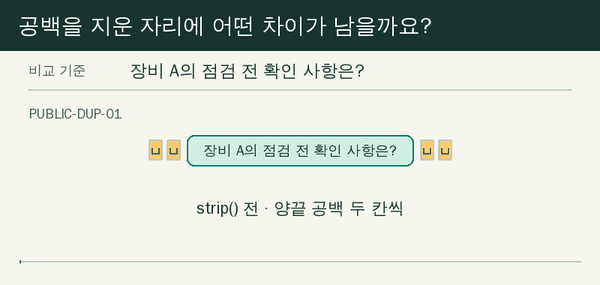

PUBLIC-DUP-01은 양끝 공백을 떼면 Q01과 같은 문장이 됩니다. 표현을 바꾼 두 번째 문항은 문자열이 달라도 기존 질문과 같은 내용을 물을 수 있어 사람이 의미를 대조합니다.
<!-- /lesson-visual detail-overlap -->


### 셀 01 · 질문 정규화와 중복 판별

개발 질문과 공개 후보 하나를 문자열 수준에서 대조합니다.

‘장비 A 점검 전에 볼 것은?’과 ‘장비 A는 점검 전 무엇을 확인하나요?’는 표기가 달라도 의도와 기대 근거 RULE-A가 같습니다. 확인용 세트에 넣기 전에 같은 능력을 다시 묻는 문항인지 검토하고 선택 이유를 남기세요.


In [1]:
development = '장비 A의 점검 전 확인 사항은?'
candidate = '  장비 A의 점검 전 확인 사항은?  '
print(candidate.strip() == development.strip())

True


True입니다. 이 후보는 독립 점수의 분모에서 제외할 수 있습니다. 문자열이 다르다는 결과만으로 의미가 새로운 질문이라고 판정할 수는 없습니다.


## 기대 근거와 실제 응답 비교

실패 분석 연습용 가상 행　질문 “B 장비의 점검 전 기준은?” / 기대 고정 장치, RULE-B 2.2절 / 가정한 검색 결과 RULE-B / 가정한 화면 답 전원 표시등 / 판단 자료는 맞게 골랐고 출력 내용이 원문과 어긋남. 실제 실행에서 중간 결과가 없으면 ‘검색 오류’라고 단정하지 말고 관찰할 단계를 먼저 적습니다.


### 검색에서 RULE-B를 찾았는데 화면 답은 왜 틀렸을까?

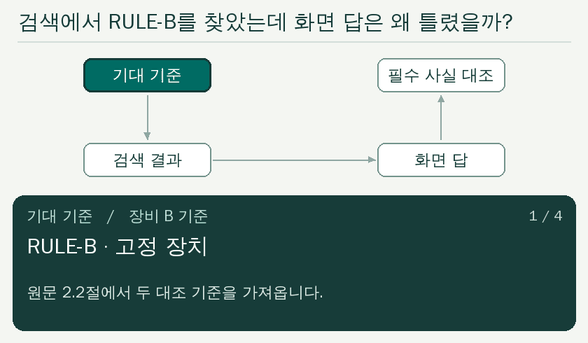

가상 실패 행의 중간 결과를 따라가며 검색 단계와 답변 단계 중 어디서 기대값이 달라지는지 찾습니다.


### 과제 02 · 선택 연습 · 기대값 불일치 기록

위 가상 행의 답에서 원문 필수 표현이 빠졌는지 확인하고 어떤 후속 관찰이 필요한지 적으세요.


In [2]:
answer = "점검 전 전원 표시등을 확인합니다."
# B의 필수 사실인 고정 장치가 답에 있는지 확인하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>answer = &quot;점검 전 전원 표시등을 확인합니다.&quot;
print(&quot;고정 장치&quot; in answer)
print(&quot;조회한 원문이 답 생성 단계에도 그대로 전달됐는지 확인한다.&quot;)</code></pre>
<p>실행 결과</p><pre><code>False
조회한 원문이 답 생성 단계에도 그대로 전달됐는지 확인한다.</code></pre>
<p>False는 답에 기대 표현이 빠졌다는 뜻입니다. 어느 함수에서 바뀌었는지 찾으려면 검색 뒤에 실제로 넘긴 자료와 화면에 도착한 답을 읽어야 합니다.</p>
</details>


## 돌아보기

확인용 자료의 보관 담당자와 열어 본 시점을 기록하세요. 이 장에 보이는 질문은 모두 공개 연습 사례입니다. 실제 비공개 확인용 질문·점수는 아직 없습니다.
